Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].


torch.Size([16, 3, 32, 32])


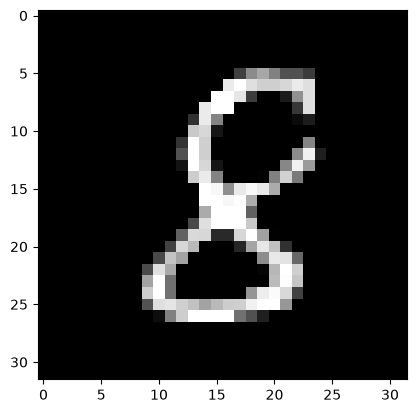

In [43]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import torch

def cuda_memory():
    if torch.cuda.is_available():
        device = torch.cuda.current_device()
        props = torch.cuda.get_device_properties(device)

        total = props.total_memory
        allocated = torch.cuda.memory_allocated(device)
        reserved = torch.cuda.memory_reserved(device)

        print(f"GPU: {props.name}")
        print(f"Total GPU memory:     {total / 1024**3:.2f} GB")
        print(f"Allocated by PyTorch: {allocated / 1024**3:.2f} GB")
        print(f"Reserved by PyTorch:  {reserved / 1024**3:.2f} GB")
        print(f"Free within PyTorch:  {(reserved - allocated) / 1024**3:.2f} GB")
    else:
        print("CUDA is not available.")
    return 

def get_dataloaders(batch_size):
    transform = transforms.Compose([
        transforms.Resize((32, 32)),                   # Optional: scale up slightly from 28x28
        transforms.Grayscale(num_output_channels=3), # Convert 1-channel MNIST to 3-channel RGB for KID
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]) # Scales [0, 1] to [-1, 1]
    ])
    seed = 42
    generator = torch.Generator()
    generator.manual_seed(seed)
    train_dataset = datasets.MNIST(root="data", train=True, download=True, transform=transform)
    train_dataloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, generator=generator)
    return train_dataloader

train_dataloader = get_dataloaders(batch_size=16) 
img, _ = next(iter(train_dataloader))
print(img.shape)  # Output: torch.Size([3, 256, 256])

plt.imshow(img[0].permute(1,2,0))


In [127]:
cuda_memory()

GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU
Total GPU memory:     5.66 GB
Allocated by PyTorch: 0.14 GB
Reserved by PyTorch:  1.51 GB
Free within PyTorch:  1.36 GB


In [44]:
from unet2 import UNet

device = "cpu" if torch.cuda.is_available() else "cuda"

model = UNet(
    in_channels=3,
    out_channels=3,
    base_channels=32,
    time_dim=128
).to(device)

# Batch of 16 RGB images
x = torch.randn(16, 3, 32, 32, device=device)

# A different timestep for every image
t = torch.randint(0, 100, (16,), device=device)

predicted_noise = model(x, t)

print("Input shape: ", x.shape)
print("Timestep shape:", t.shape)
print("Output shape:", predicted_noise.shape)

Input shape:  torch.Size([16, 3, 32, 32])
Timestep shape: torch.Size([16])
Output shape: torch.Size([16, 3, 32, 32])


# Diffusion train

torch.Size([100])


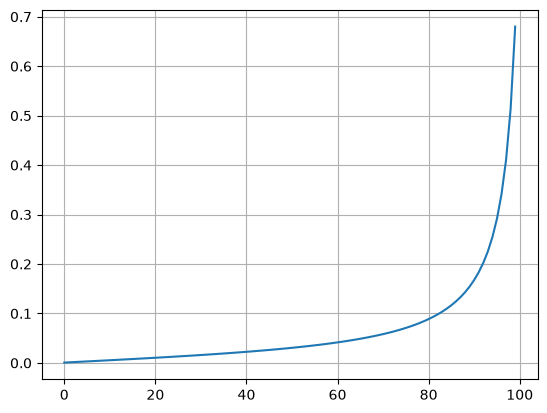

In [45]:

def diffusion_schedule(T, max_signal_rate=0.9999, min_signal_rate=0.02):
    # Generate T + 1 diffusion times
    t = torch.linspace(0, 1, T + 1)
    # Convert signal limits to angles
    start_angle = torch.arccos(torch.tensor(max_signal_rate))
    end_angle = torch.arccos(torch.tensor(min_signal_rate))
    # Calculate signal rates
    angles = start_angle + t * (end_angle - start_angle)
    signal_rates = torch.cos(angles)
    # Calculate cumulative signal coefficients
    alpha_bars = signal_rates ** 2

    # Normalize initial cumulative signal to 1
    alpha_bars = alpha_bars / alpha_bars[0]

    # Calculate T beta values
    betas = 1 - alpha_bars[1:] / alpha_bars[:-1]

    return torch.clamp(betas, min=0.0, max=0.999)

T = 100
betas = diffusion_schedule(T)

print(betas.shape)  # torch.Size([1000])

plt.plot(betas)
plt.grid()

In [46]:
import gc
import torch.nn.functional as F
gc.collect()
torch.cuda.empty_cache()
cuda_memory()

GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU
Total GPU memory:     5.66 GB
Allocated by PyTorch: 0.18 GB
Reserved by PyTorch:  0.94 GB
Free within PyTorch:  0.75 GB


In [47]:
import torch

@torch.no_grad()
def reverse_sample(model, shape, T, betas, alpha_cumprod, sigmas=None, device="cuda"):
    """
    Implements the reverse diffusion sampling process.
    
    Args:
        model: The trained noise-prediction model (e.g., UNet) g_t.
        shape: Shape of the output sample tensor, e.g., (batch_size, channels, H, W).
        T: Total number of timesteps.
        betas: Tensor of beta values of length T.
        alpha_cumprod: Tensor of alpha values of length T.
        sigmas: Optional tensor or function for the noise scaling factor sigma_t.
        device: Computation device ('cuda' or 'cpu').
    """
    model.eval()
    
    z = torch.randn(shape, device=device)
    
    for t in range(T, 1, -1):
        idx = t - 1  
        
        beta_t = betas[idx]
        alpha_t = alpha_cumprod[idx]
        t_batch = torch.full((shape[0],), idx, device=device, dtype=torch.long)
        g_t = model(z, t_batch)
        coef_z = 1.0 / torch.sqrt(1.0 - beta_t)
        coef_g = beta_t / (torch.sqrt(1.0 - alpha_t) * torch.sqrt(1.0 - beta_t))
        z_hat = coef_z * z - coef_g * g_t
        
        epsilon = torch.randn_like(z)
        
        sigma_t = beta_t.sqrt() if sigmas is None else sigmas[idx]
        z = z_hat + sigma_t * epsilon

    beta_1 = betas[0]
    alpha_1 = alpha_cumprod[0]
    t_1 = torch.zeros((shape[0],), device=device, dtype=torch.long)
    g_1 = model(z, t_1)
    
    coef_z1 = 1.0 / torch.sqrt(1.0 - beta_1)
    coef_g1 = beta_1 / (torch.sqrt(1.0 - alpha_1) * torch.sqrt(1.0 - beta_1))
    
    x = coef_z1 * z - coef_g1 * g_1
    return x



# Hyperparameters

In [48]:
import torch
import torch.nn.functional as F
import torch.optim as optim
from tqdm import tqdm

batch_size = 16
dataloader = get_dataloaders(batch_size=batch_size) 

T = 100
epochs = 5
model = UNet(in_channels=3, out_channels=3)
optimizer = optim.AdamW(
    model.parameters(),
    lr=1e-4,  # Learning rate
    weight_decay=1e-4,  # L2 penalty (optional)
)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"DEVICE={device}")
model = model.to(device)

# Generate the beta schedule
betas = diffusion_schedule(T).to(device)

# Precompute cumulative signal coefficients
alpha_cumprod = torch.cumprod(1.0 - betas, dim=0).to(device)

batch_losses = []
kid_steps    = []
kid_means    = []

DEVICE=cuda


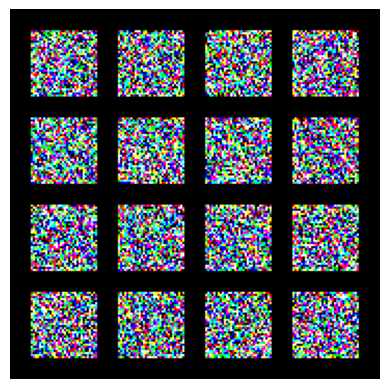

(0.6481233239173889, 0.00365434936247766)

In [49]:
import torchvision
from torchmetrics.image.kid import KernelInceptionDistance

def vizualize_batch(model, batch_size, T, betas, alpha_cumprod, device):
    batch_results = reverse_sample(model=model, 
                        shape=(batch_size, 3, 32, 32), 
                        T=T, 
                        betas=betas, 
                        alpha_cumprod=alpha_cumprod, 
                        sigmas=None, 
                        device=device)
    grid_img = torchvision.utils.make_grid(batch_results.cpu(), nrow=4, padding=10)
    plt.axis("off")
    _=plt.imshow(grid_img.permute(1, 2, 0).clamp(0,1).numpy())
    plt.show()

def evaluate(dataloader,
             model, 
             T, 
             betas, 
             alpha_cumprod, 
             device):
    
    # Suppose your subset_size is 100, but your batch size is 32
    kid = KernelInceptionDistance(subset_size=100).to(device)

    # Accumulate across multiple batches until you hit at least 100 images
    i = 0
    for real_imgs, _ in dataloader:
        # real_imgs.shape is e.g. [32, 3, 256, 256]
        batch_size = len(real_imgs)
        fake_imgs = reverse_sample(model=model, 
                                   shape=real_imgs.shape, 
                                   T=T, 
                                   betas=betas, 
                                   alpha_cumprod=alpha_cumprod, 
                                   sigmas=None, 
                                   device=device)

        # Preprocess fake images to match requirements [0, 255] uint8
        fake_imgs = ((fake_imgs * 0.5 + 0.5) * 255.0).byte()
        real_imgs = ((real_imgs * 0.5 + 0.5) * 255.0).clamp(0, 255).byte()
        
        # Feed them into the KID metric (it keeps an internal buffer)
        kid.update(real_imgs.to(device), real=True)
        kid.update(fake_imgs.to(device), real=False)
        i += 1
        # Optional: break once you've collected enough batches (e.g., 4 batches * 32 = 128 images)
        if i*batch_size >= 100:
            break

    kid_mean, kid_std = kid.compute()
    return kid_mean.cpu().item(), kid_std.cpu().item()

vizualize_batch(model, batch_size, T, betas, alpha_cumprod, "cuda")
evaluate(dataloader,model, T, betas, alpha_cumprod, device)


Epoch 1/5:  27%|██▋       | 998/3750 [00:19<00:54, 50.47it/s]


--- Running KID Evaluation at Step 1000 ---
KID Score: 0.51774 ± 0.00299



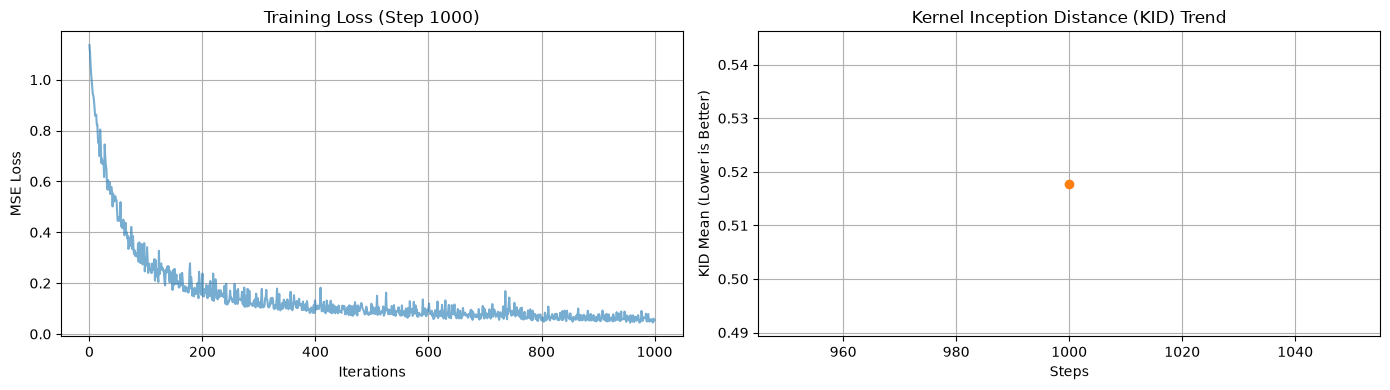

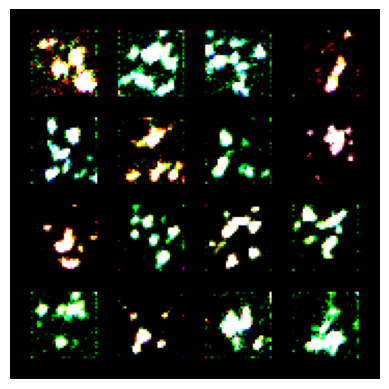

Epoch 1/5:  53%|█████▎    | 1998/3750 [00:43<00:34, 51.41it/s]


--- Running KID Evaluation at Step 2000 ---
KID Score: 0.37226 ± 0.00266



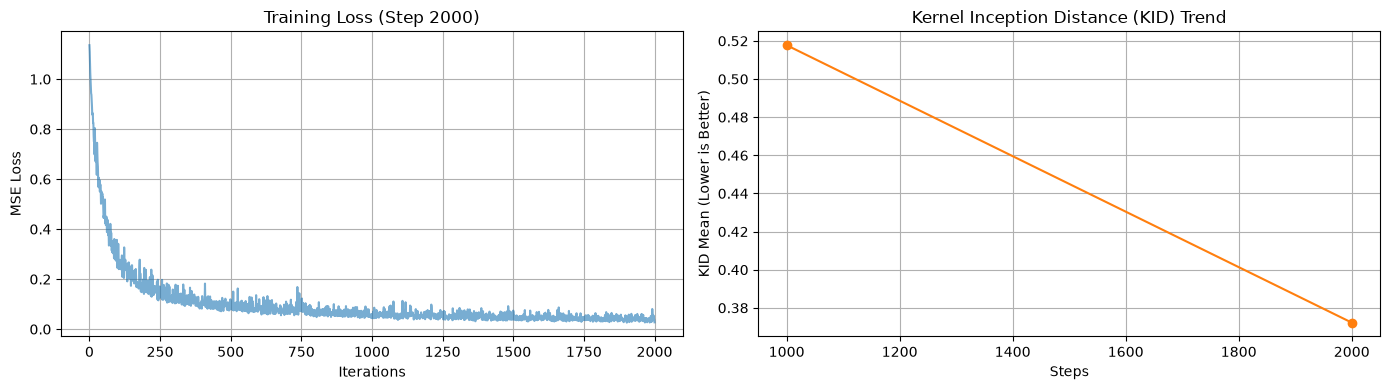

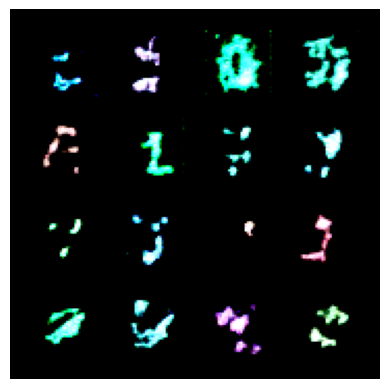

Epoch 1/5:  80%|███████▉  | 2997/3750 [01:07<00:14, 51.61it/s]


--- Running KID Evaluation at Step 3000 ---
KID Score: 0.33355 ± 0.00329



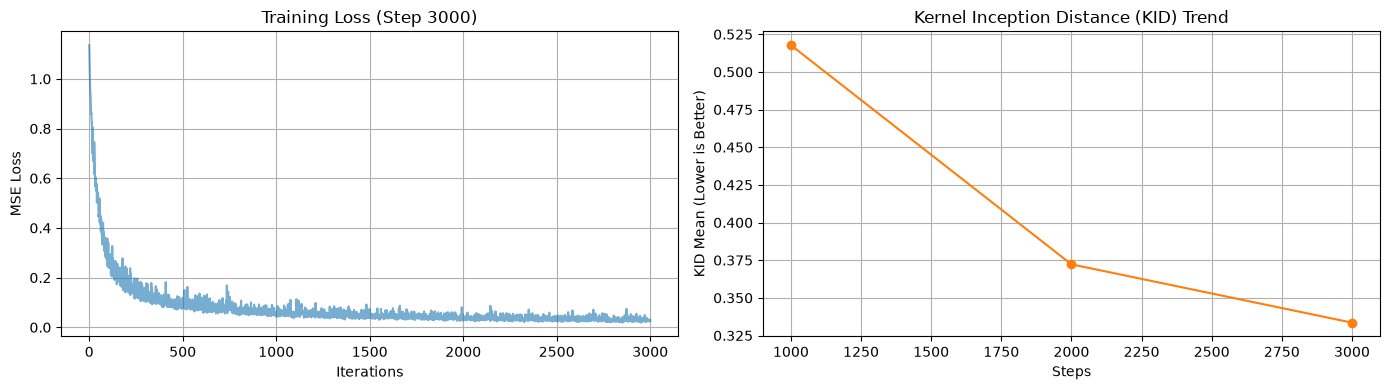

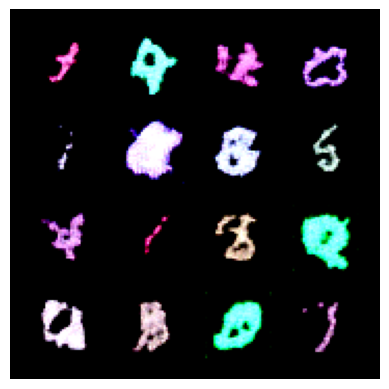

Epoch 1/5: 100%|██████████| 3750/3750 [01:27<00:00, 43.06it/s]


EPOCH LOSS=0.068260


Epoch 2/5:   7%|▋         | 245/3750 [00:04<01:08, 50.94it/s]


--- Running KID Evaluation at Step 4000 ---
KID Score: 0.29607 ± 0.00281



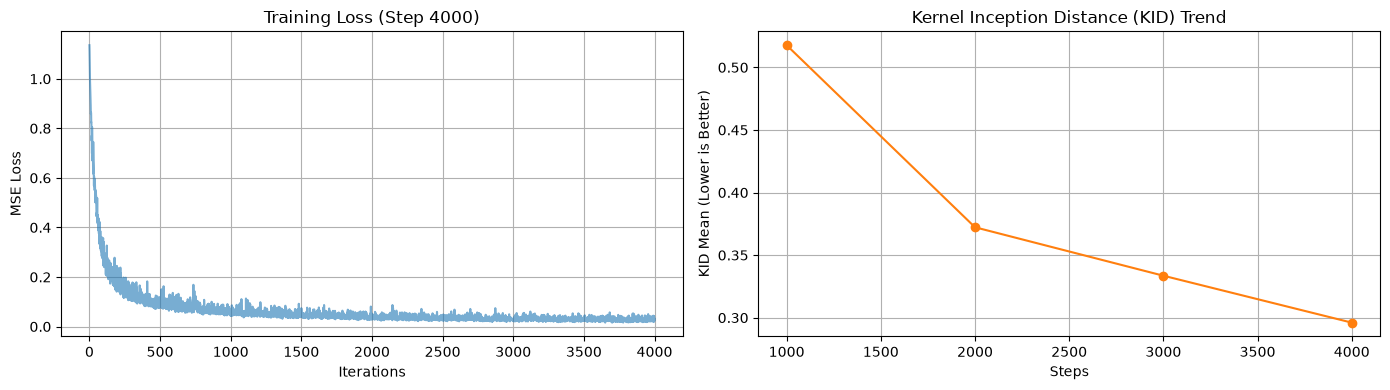

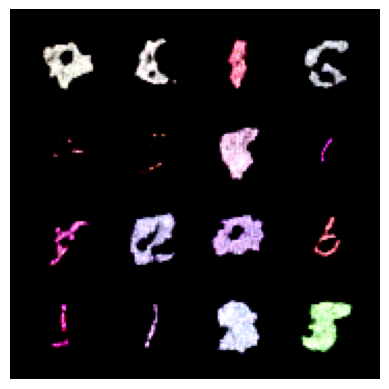

Epoch 2/5:  33%|███▎      | 1247/3750 [00:29<00:52, 47.68it/s]


--- Running KID Evaluation at Step 5000 ---
KID Score: 0.28781 ± 0.00283



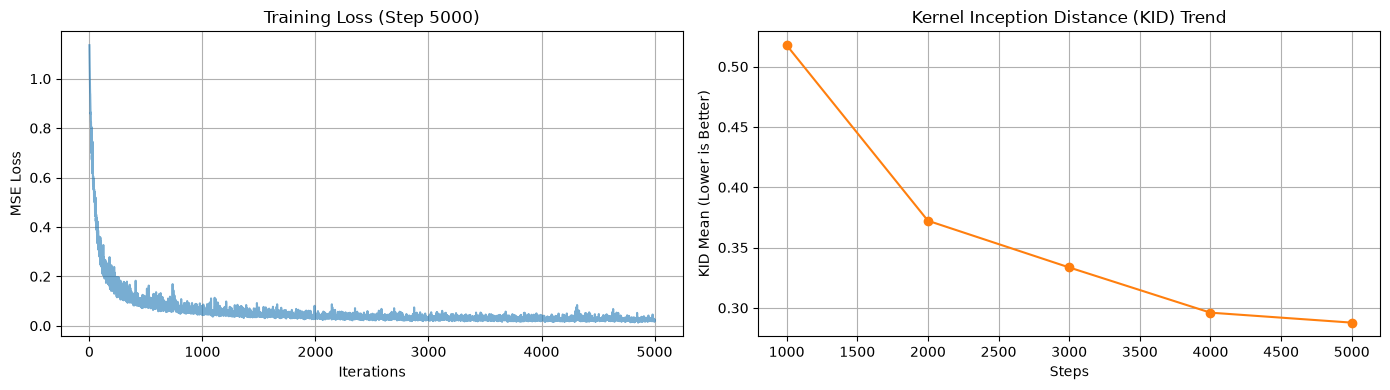

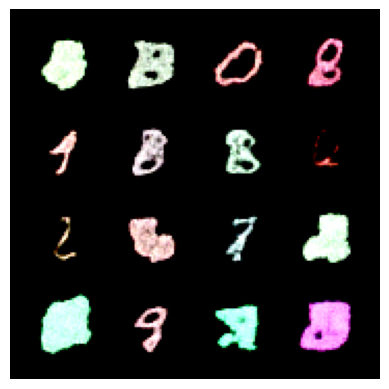

Epoch 2/5:  60%|██████    | 2250/3750 [00:53<00:30, 49.11it/s]


--- Running KID Evaluation at Step 6000 ---
KID Score: 0.28772 ± 0.00319



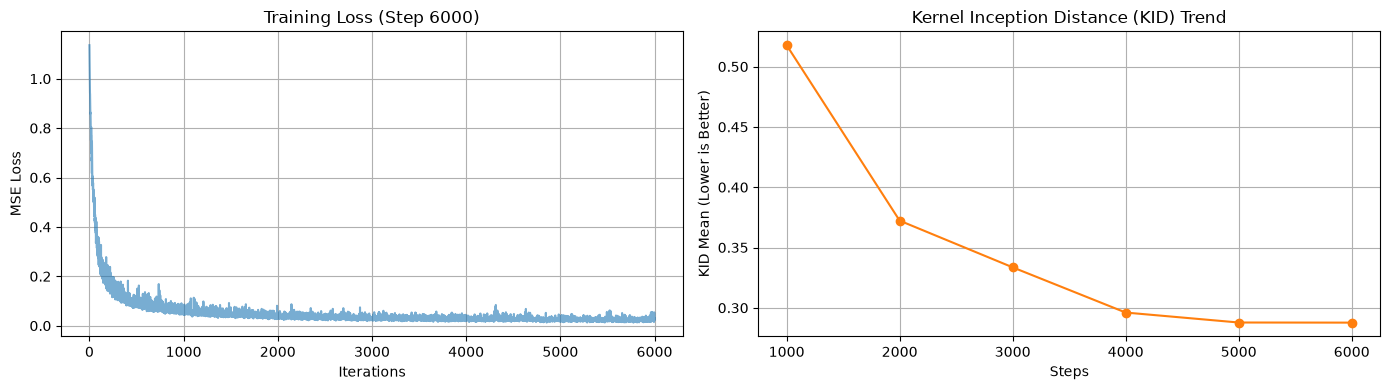

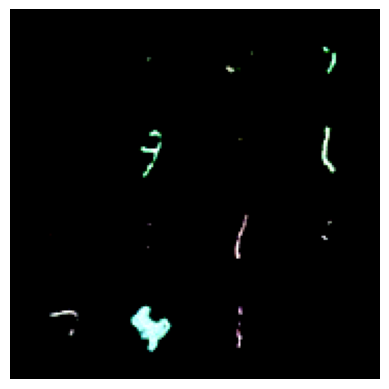

Epoch 2/5:  87%|████████▋ | 3245/3750 [01:17<00:10, 49.58it/s]


--- Running KID Evaluation at Step 7000 ---
KID Score: 0.25400 ± 0.00259



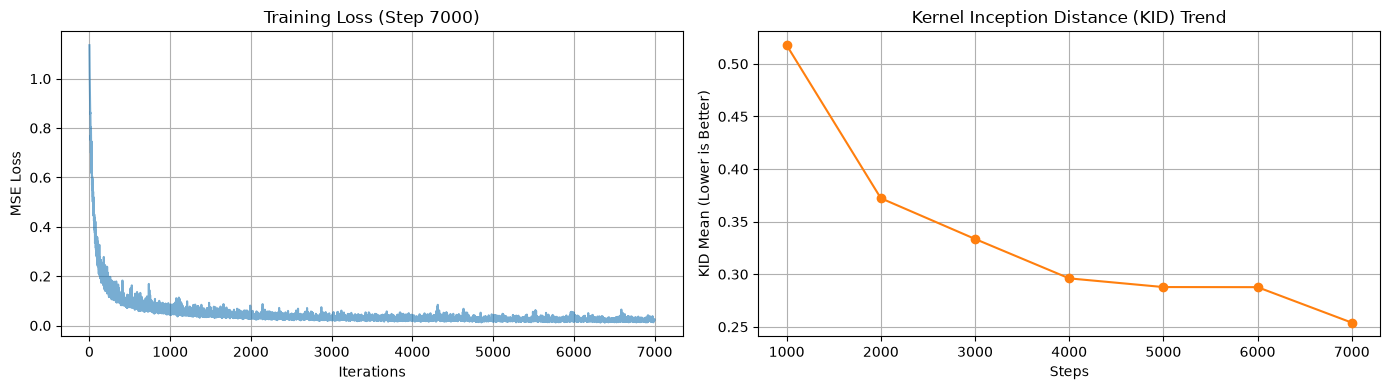

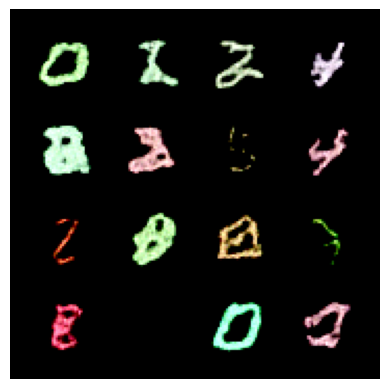

Epoch 2/5: 100%|██████████| 3750/3750 [01:32<00:00, 40.44it/s]


EPOCH LOSS=0.025136


Epoch 3/5:  13%|█▎        | 499/3750 [00:10<01:03, 51.18it/s]


--- Running KID Evaluation at Step 8000 ---
KID Score: 0.30964 ± 0.00302



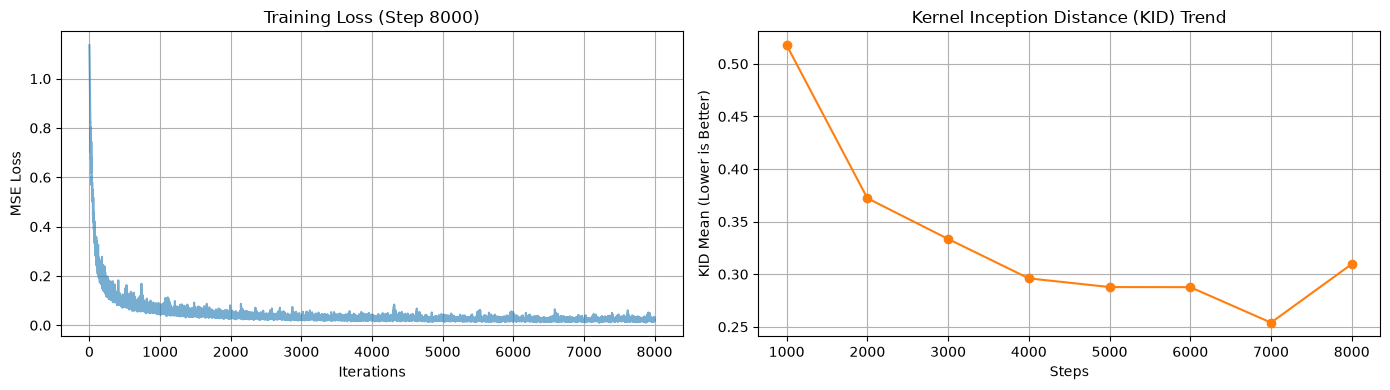

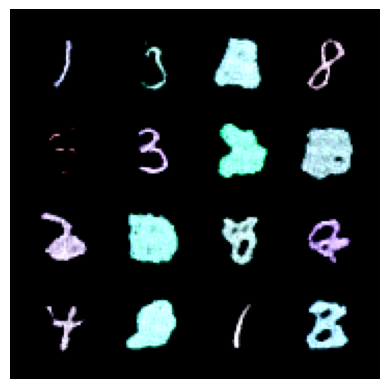

Epoch 3/5:  40%|███▉      | 1496/3750 [00:34<00:44, 51.12it/s]


--- Running KID Evaluation at Step 9000 ---
KID Score: 0.30136 ± 0.00349



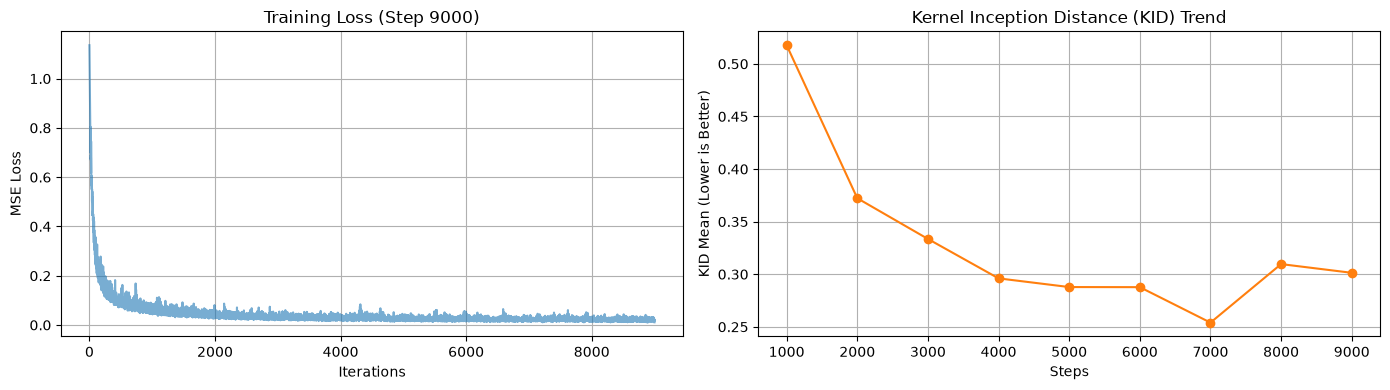

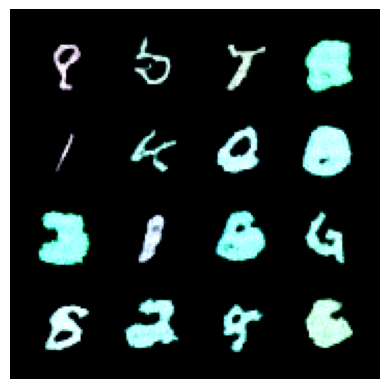

Epoch 3/5:  67%|██████▋   | 2497/3750 [00:58<00:24, 51.98it/s]


--- Running KID Evaluation at Step 10000 ---
KID Score: 0.24100 ± 0.00273



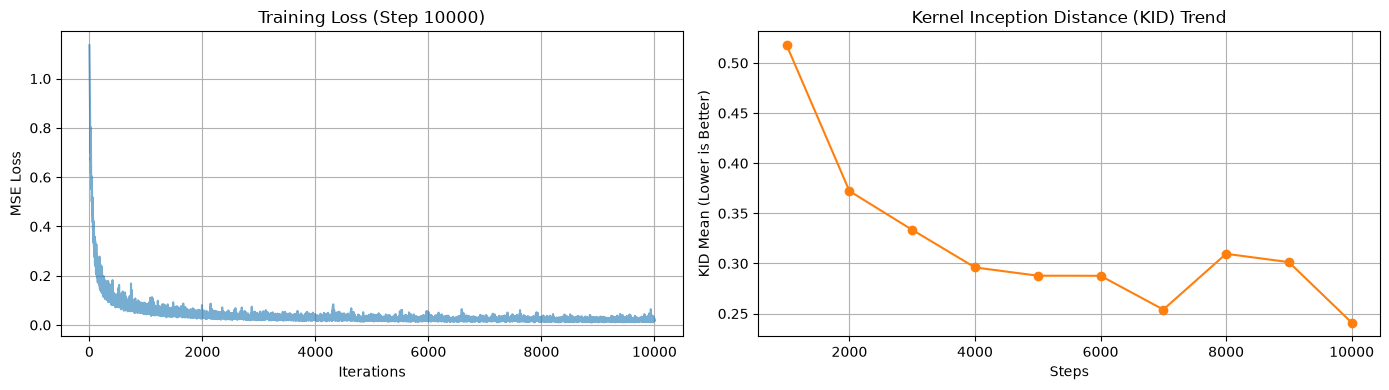

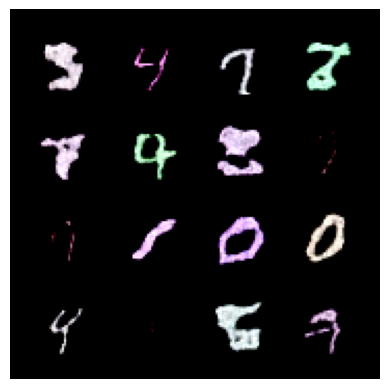

Epoch 3/5:  93%|█████████▎| 3497/3750 [01:22<00:05, 48.40it/s]


--- Running KID Evaluation at Step 11000 ---
KID Score: 0.29013 ± 0.00383



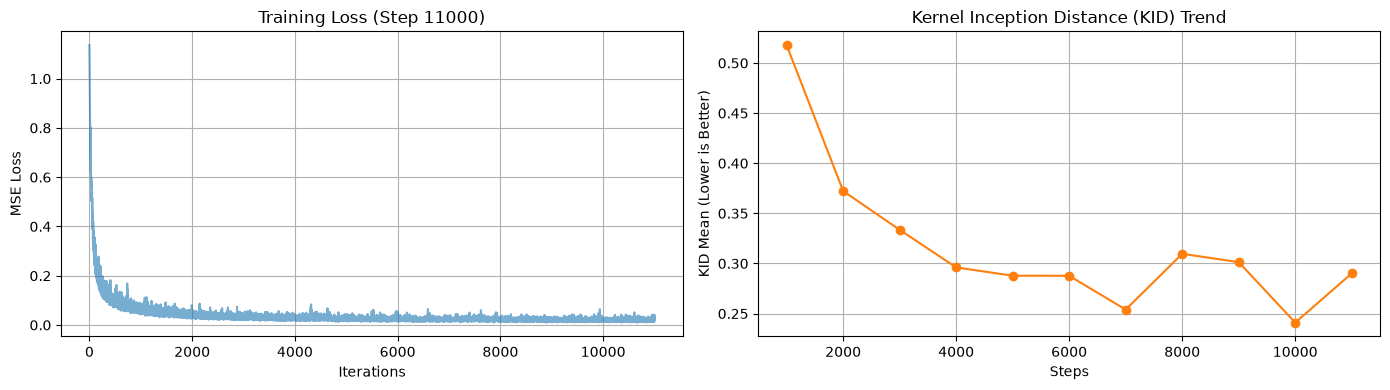

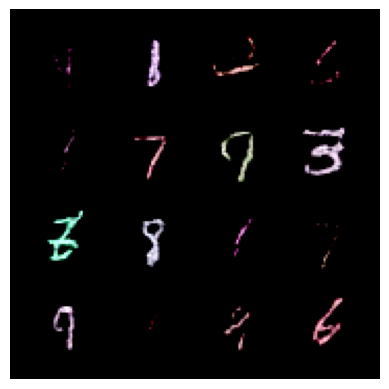

Epoch 3/5: 100%|██████████| 3750/3750 [01:32<00:00, 40.58it/s]


EPOCH LOSS=0.020979


Epoch 4/5:  20%|█▉        | 746/3750 [00:14<00:57, 51.87it/s]


--- Running KID Evaluation at Step 12000 ---
KID Score: 0.29168 ± 0.00317



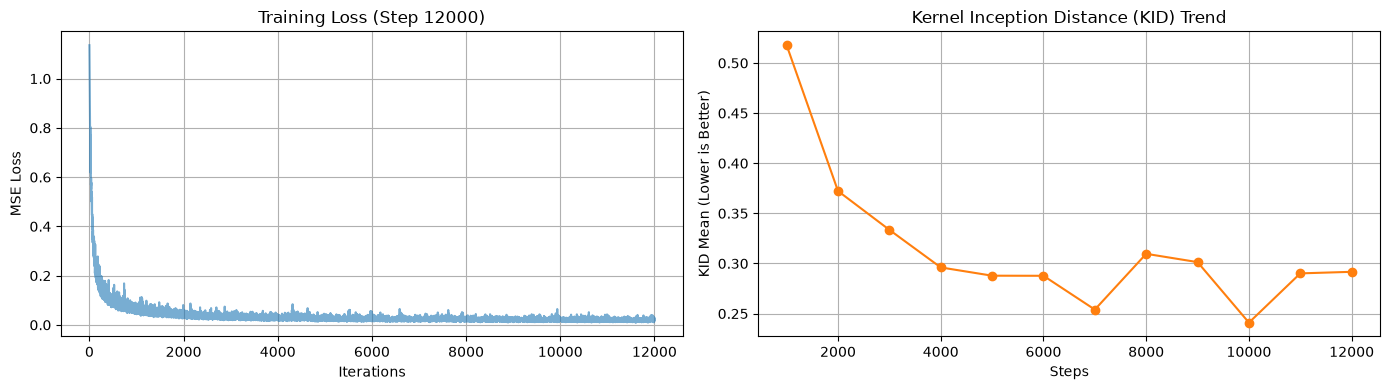

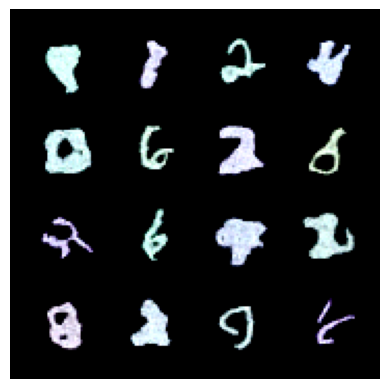

Epoch 4/5:  47%|████▋     | 1750/3750 [00:38<00:38, 52.00it/s]


--- Running KID Evaluation at Step 13000 ---
KID Score: 0.26172 ± 0.00359



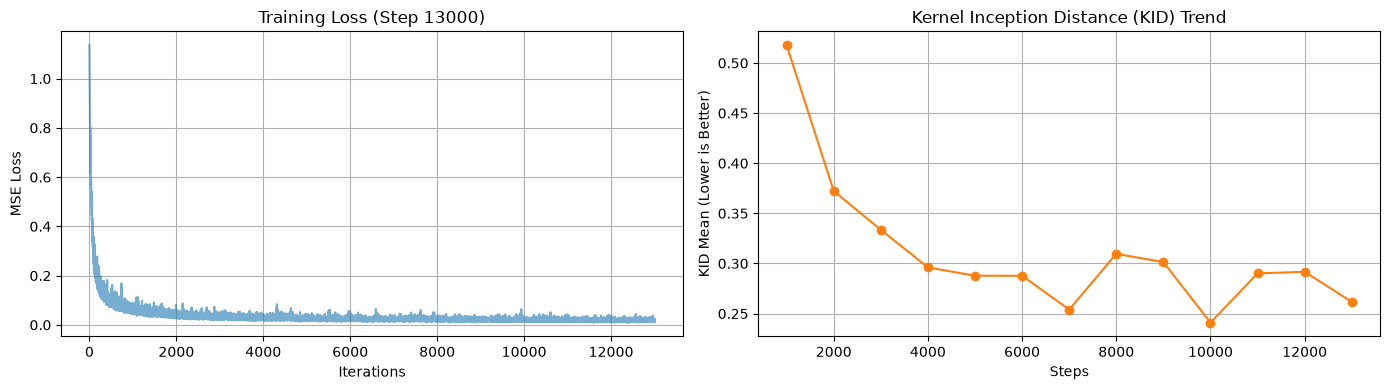

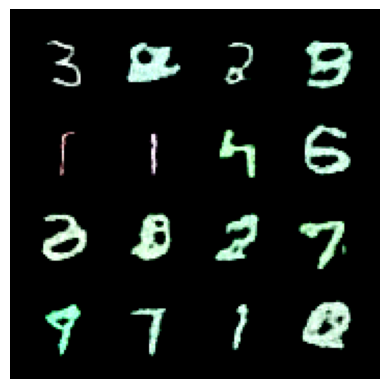

Epoch 4/5:  73%|███████▎  | 2747/3750 [01:02<00:19, 51.39it/s]


--- Running KID Evaluation at Step 14000 ---
KID Score: 0.26298 ± 0.00312



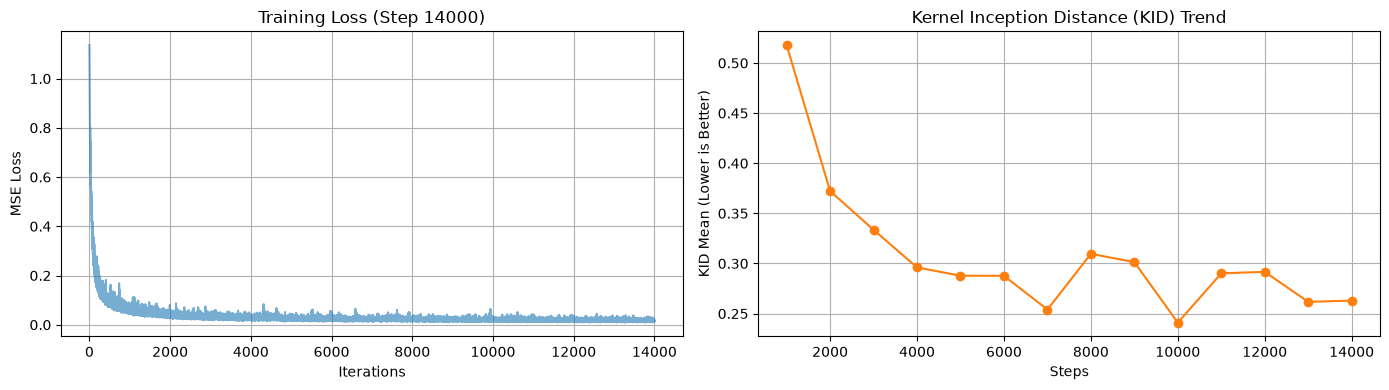

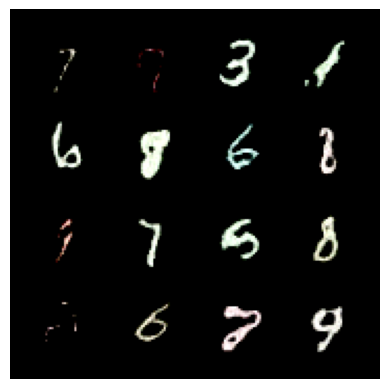

Epoch 4/5: 100%|██████████| 3750/3750 [01:26<00:00, 43.26it/s]


EPOCH LOSS=0.018582


Epoch 5/5:   0%|          | 0/3750 [00:00<?, ?it/s]


--- Running KID Evaluation at Step 15000 ---
KID Score: 0.27017 ± 0.00334



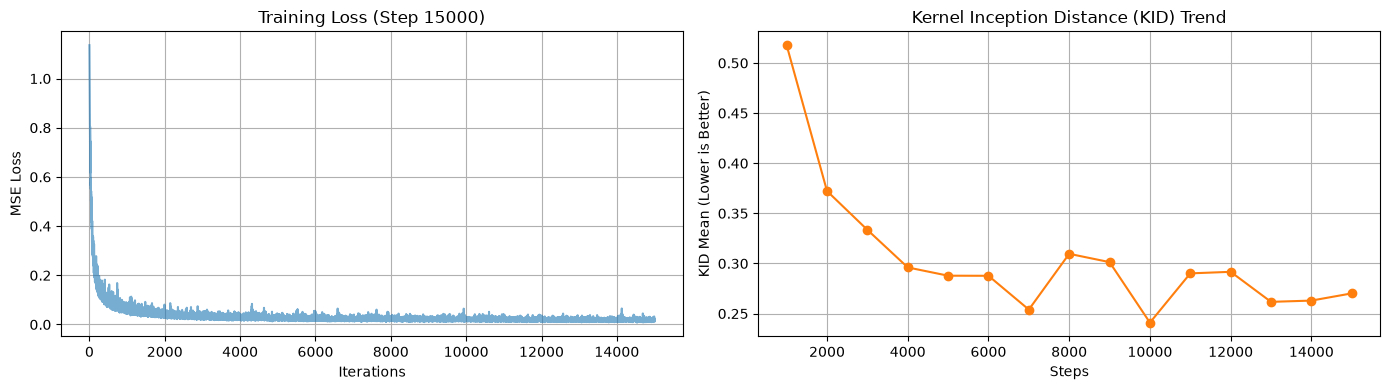

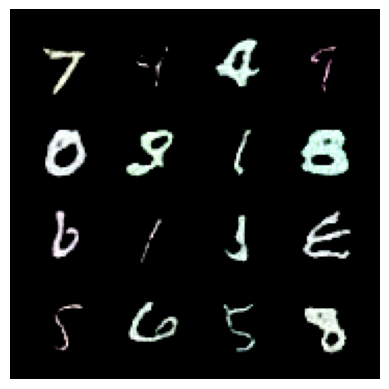

Epoch 5/5:  27%|██▋       | 995/3750 [00:23<00:58, 47.45it/s]


--- Running KID Evaluation at Step 16000 ---
KID Score: 0.25641 ± 0.00363



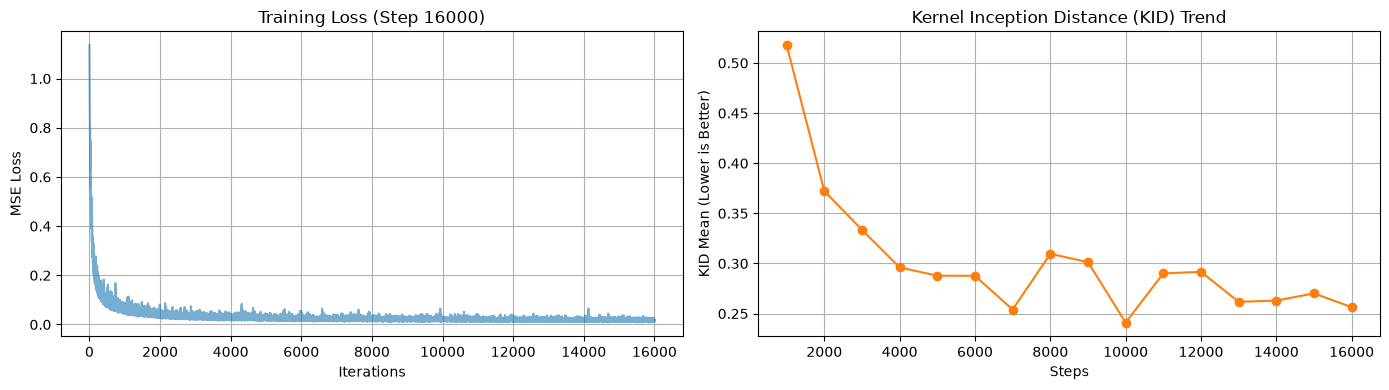

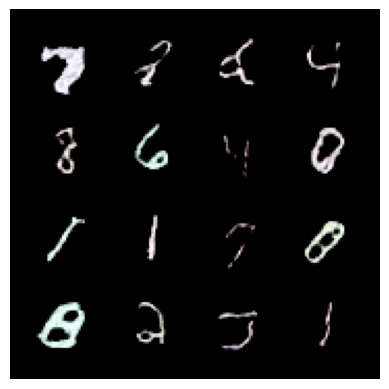

Epoch 5/5:  53%|█████▎    | 1999/3750 [00:48<00:33, 52.10it/s]


--- Running KID Evaluation at Step 17000 ---
KID Score: 0.25605 ± 0.00315



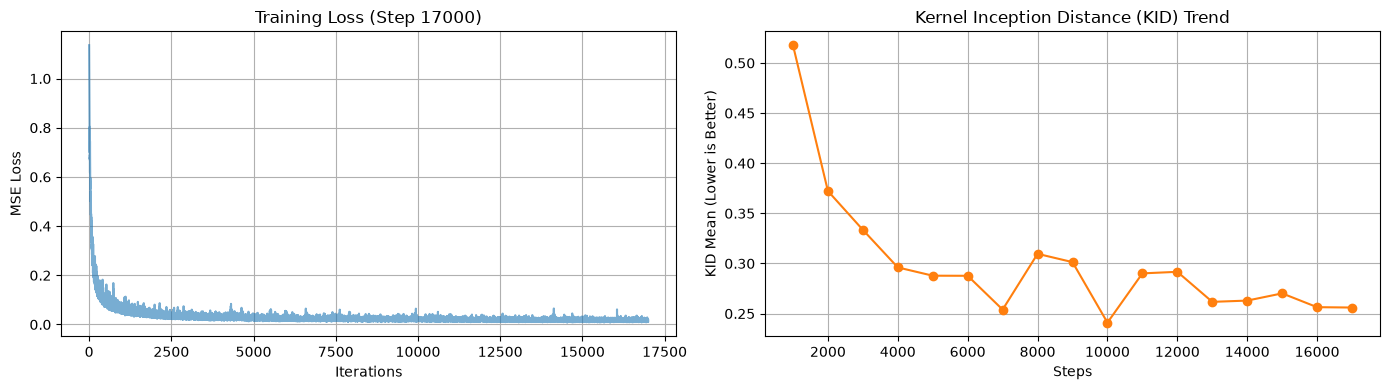

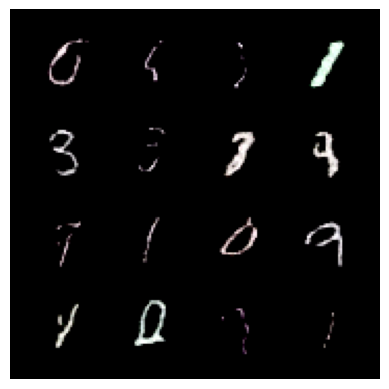

Epoch 5/5:  80%|████████  | 3000/3750 [01:11<00:14, 51.79it/s]


--- Running KID Evaluation at Step 18000 ---
KID Score: 0.30281 ± 0.00358



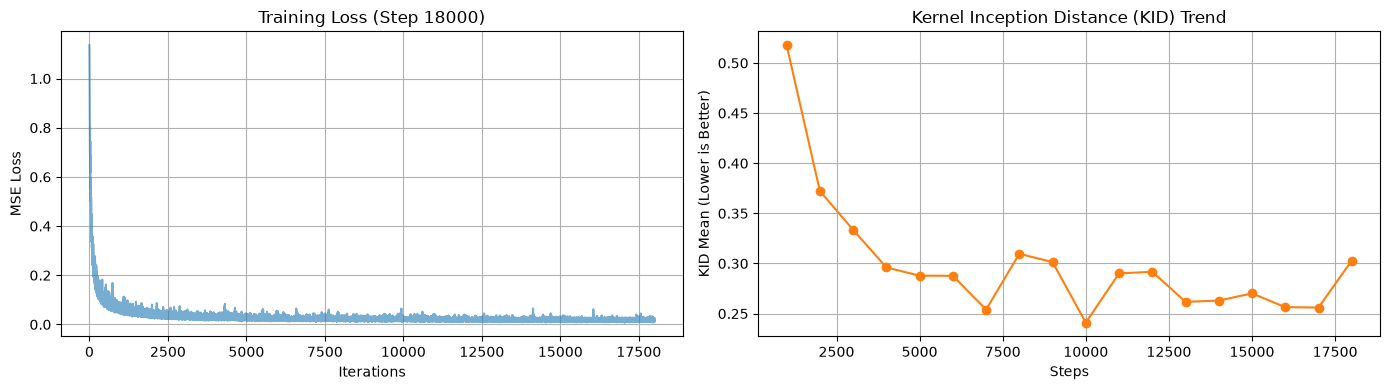

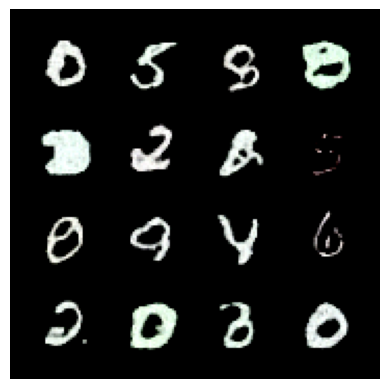

Epoch 5/5: 100%|██████████| 3750/3750 [01:31<00:00, 40.97it/s]


EPOCH LOSS=0.017308


In [50]:
def diagnostics(step, batch_losses, kid_steps, kid_means, model, dataloader, T, betas, alpha_cumprod, device):
    print(f"\n--- Running KID Evaluation at Step {step} ---")
    kid_mean, kid_std = evaluate(dataloader, model, T, betas, alpha_cumprod, device)
    print(f"KID Score: {kid_mean:.5f} ± {kid_std:.5f}\n")
    
    # Store history for plotting
    kid_steps.append(step)
    kid_means.append(kid_mean)

    # Plot Loss and KID side-by-side or stacked
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    
    # Plot Training Loss
    axes[0].plot(batch_losses, color='tab:blue', alpha=0.6)
    axes[0].set_title(f"Training Loss (Step {step}) = {batch_losses[-1]}")
    axes[0].set_xlabel("Iterations")
    axes[0].set_ylabel("MSE Loss")
    axes[0].grid(True)
    
    # Plot KID Score Trend
    axes[1].plot(kid_steps, kid_means, marker='o', color='tab:orange', linestyle='-')
    axes[1].set_title("Kernel Inception Distance (KID) Trend")
    axes[1].set_xlabel("Steps")
    axes[1].set_ylabel("KID Mean (Lower is Better)")
    axes[1].grid(True)
    
    plt.tight_layout()
    plt.show()

    vizualize_batch(model, batch_size, T, betas, alpha_cumprod, "cuda")



for epoch in range(epochs):
    model.train()
    epoch_loss = 0.0
    for i, (img_batch, _) in enumerate(tqdm(dataloader, desc=f"Epoch {epoch + 1}/{epochs}")):
        global_step = epoch * len(dataloader) + i

        optimizer.zero_grad()
        img_batch = img_batch.to(device) # img_batch: 16, 3, 256, 256

        t = torch.randint(0, T, (batch_size,), device=device)
        epsilon = torch.randn_like(img_batch) # 16, 3, 256, 256

        alpha_bar_t = alpha_cumprod[t]
        alpha_bar_t = alpha_bar_t.view(-1, 1, 1, 1)

        noisy_images = (
            torch.sqrt(alpha_bar_t) * img_batch
            + torch.sqrt(1.0 - alpha_bar_t) * epsilon
        )

        predicted_noise = model(noisy_images, t)

        batch_loss = F.mse_loss(predicted_noise, epsilon)
        batch_loss.backward()

        epoch_loss += batch_loss.item()
        optimizer.step()
        batch_losses.append(batch_loss.item())

        if global_step != 0 and global_step % 1000 == 0:
            diagnostics(
                step=global_step, 
                batch_losses=batch_losses, 
                kid_steps=kid_steps, 
                kid_means=kid_means, 
                model=model, 
                dataloader=dataloader, 
                T=T, 
                betas=betas, 
                alpha_cumprod=alpha_cumprod, 
                device=device
            )
    epoch_loss /= len(dataloader)
    print(f"EPOCH LOSS={epoch_loss:.6f}")
    torch.save(model.state_dict(), f"unet_weights_epoch_{epoch+1}.pth")

    
# Save model weights

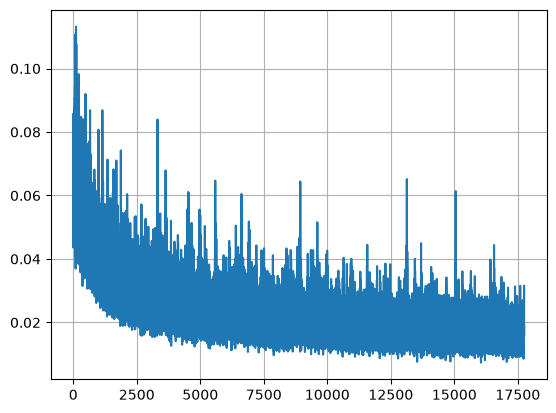

In [51]:
plt.plot(batch_losses[1000:])
plt.grid()

# Sampling and vizualization

In [54]:
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
weights_path = "unet_weights_epoch_5.pth"
model.load_state_dict(torch.load(weights_path, map_location=device))

<All keys matched successfully>

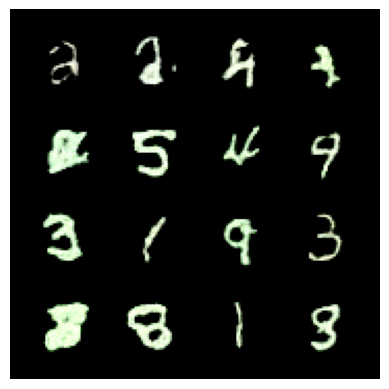

In [60]:

batch_size = 16
betas = diffusion_schedule(T).to(device)
alpha_cumprod = torch.cumprod(1.0 - betas, dim=0)
vizualize_batch(model, batch_size, T, betas, alpha_cumprod, device)
